# 06 Explanations and the map

Phase 6 packages the final model for the app: every player's top career comps, a "why similar" breakdown for each player's top 5, 2D map coordinates for every season, and the profile vectors that let the app apply the lambda slider live. The final model is seed 2026 of the Phase 5 pipeline (the Phase 3 encoder, season centring at alpha 0.5, career score with centre 0.25, peak 0.75, lambda 0). The breakdowns use integrated gradients, which credit each of the 15 style stats with its share of the score; because an explanation can be fluent and still wrong, two checks run on it: completeness (the credits must add up to the score change they explain) and a deletion test (removing the most-credited stats must hurt the score more than removing random ones).

This notebook **only reads**. It reads `exports/` (git-ignored; regenerate with `python src/precompute.py`) and recomputes the checks on a small sample from the saved Phase 4 weights. It trains nothing and writes nothing. Hold-outs are excluded, and no metric is computed on the test split.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from baselines import STYLE
from career import build_profiles, scales
from era_adversary import SeasonCentred
from evaluate_era import load_adv, splits
from explain import DifferentiableCareer, deletion_test, explain_pair, player_inputs

EX = ROOT / "exports"
pd.set_option("display.width", 170)
players = pd.DataFrame(json.loads((EX / "players.json").read_text())).set_index("player_id")
comps = json.loads((EX / "comps.json").read_text())
why = json.loads((EX / "why.json").read_text())
umap_xy = pd.read_csv(EX / "seasons_umap.csv")
manifest = json.loads((EX / "manifest.json").read_text())
report_text = (ROOT / "reports" / "phase6_explain.md").read_text()

# the final model, rebuilt from the saved weights exactly as precompute.py does
df, train, _, _, pool = splits()
pool = pool.reset_index(drop=True)
base = load_adv(0.0, 2026)
model = SeasonCentred(base, 0.5).fit(train)
sc = scales(build_profiles(model, train, min_seasons=2))
diff = DifferentiableCareer(base.model, model.means, 0.5, 0.25, 0.75, sc)
inputs = {}
def inp(pid):
    if pid not in inputs:
        inputs[pid] = player_inputs(pool, pid)
    return inputs[pid]
name = players["player"].to_dict()
print(f"{len(players):,} players, {len(umap_xy):,} seasons in exports; model: {manifest['model']['encoder']}")

2,467 players, 14,672 seasons in exports; model: models/phase4/adversary_lambda0.0_s2026.pt


## 1. Why similar

For each pair, the 15 style stats ranked by how much each makes the two careers alike (positive) or unlike (negative) compared with an average player. Jordan/Kobe and Stockton/Chris Paul are read from `why.json` (each is in the other's top 5). Rodman's comp Reggie Evans is his sixth comp, outside the stored top 5, so that breakdown is recomputed with `explain.explain_pair`.

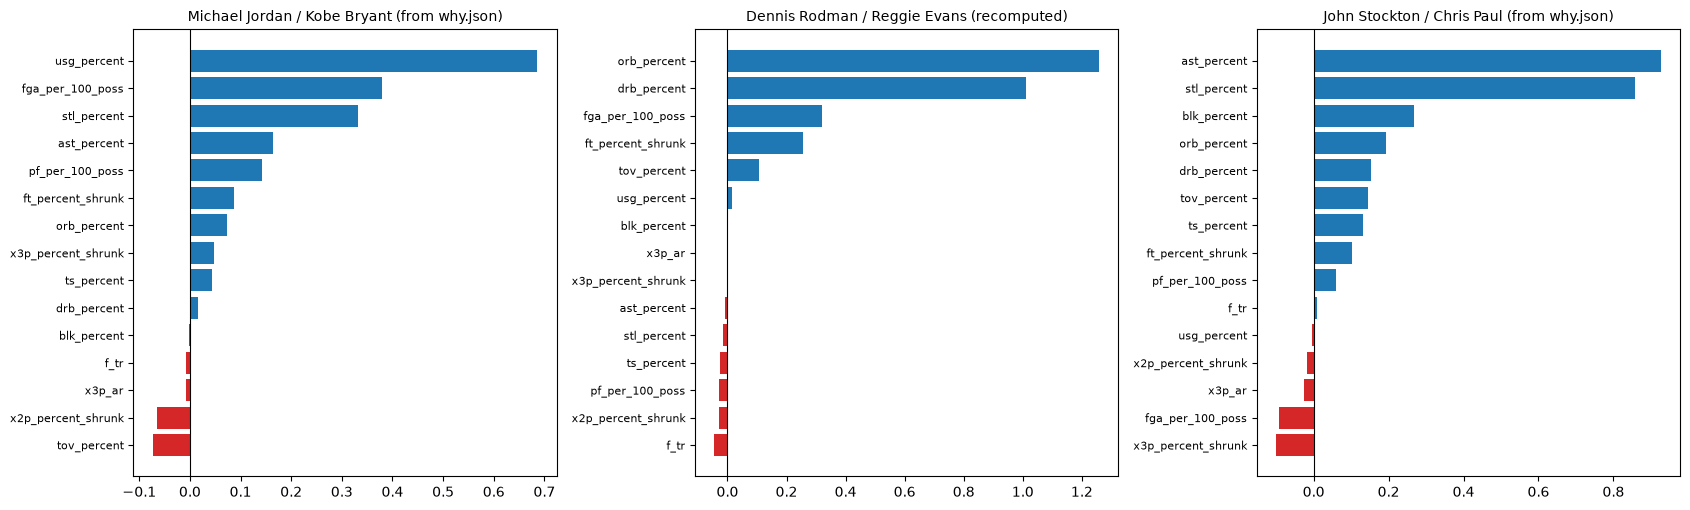

Michael Jordan / Kobe Bryant: most alike on usg_percent (+0.69), fga_per_100_poss (+0.38), stl_percent (+0.33)
Dennis Rodman / Reggie Evans: most alike on orb_percent (+1.26), drb_percent (+1.01), fga_per_100_poss (+0.32)
John Stockton / Chris Paul: most alike on ast_percent (+0.93), stl_percent (+0.86), blk_percent (+0.27)


In [2]:
def breakdown(a, b):
    if b in why.get(a, {}):
        return why[a][b], "from why.json"
    return explain_pair(diff, inp(a), inp(b))["per_feature"], "recomputed"

pairs = [("jordami01", "bryanko01"), ("rodmade01", "evansre01"), ("stockjo01", "paulch01")]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, (a, b) in zip(axes, pairs):
    bd, src = breakdown(a, b)
    s = pd.Series(bd).sort_values()
    ax.barh(s.index, s.values, color=["tab:red" if v < 0 else "tab:blue" for v in s.values])
    ax.axvline(0, c="black", lw=0.8)
    ax.set_title(f"{name[a]} / {name[b]} ({src})", fontsize=10); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
for a, b in pairs:
    bd, _ = breakdown(a, b)
    top = sorted(bd.items(), key=lambda kv: -kv[1])[:3]
    print(f"{name[a]} / {name[b]}: most alike on " + ", ".join(f"{k} ({v:+.2f})" for k, v in top))

## 2. Checks

Recomputed on 50 random (player, top-5 comp) pairs. Left: the completeness error of each explanation (how far the credits are from the score change they should add up to). Right: the deletion test. For each pair, set the player's 3 most-credited stats to league average and measure the score drop (y), against the average drop from 3 random stats (x). Faithful explanations sit above the diagonal.

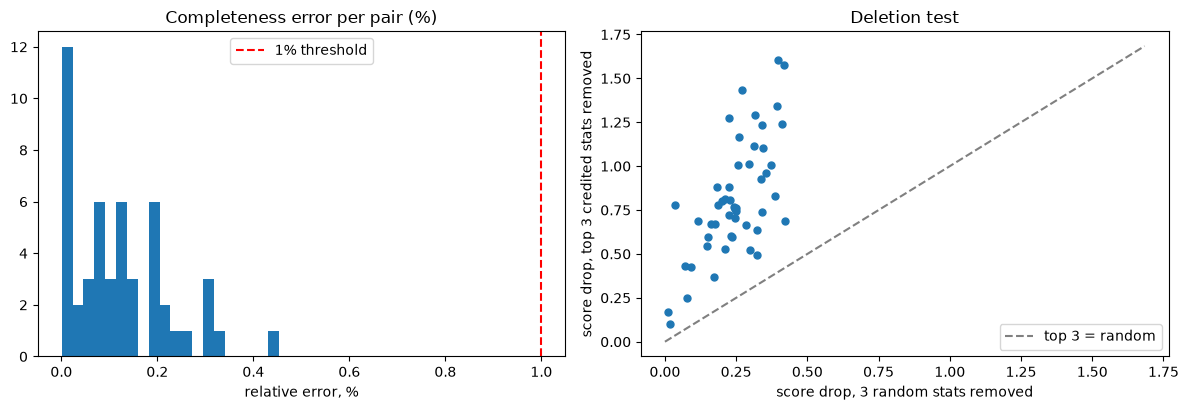

50 pairs: completeness error mean 0.123%, max 0.454%; top-3 drop 0.814 vs random 0.246; top 3 matter more in 100% of pairs
Full run (reports/phase6_explain.md):
| Completeness error (attributions vs score change), mean | 0.106% |
| Completeness error, max | 2.329% |
| Pairs with completeness error under 1% | 100.0% |
| Deletion test: mean score drop, top-3 credited features set to average | 0.754 |
| Deletion test: mean score drop, 3 random features | 0.224 |
| Pairs where the top 3 matter more than random | 100.0% (of 300) |


In [3]:
rng = np.random.default_rng(2026)
all_pairs = [(a, b) for a in why for b in why[a]]
sample = [all_pairs[i] for i in rng.choice(len(all_pairs), 50, replace=False)]
errs, drops = [], []
for a, b in sample:
    ex = explain_pair(diff, inp(a), inp(b))
    errs.append(ex["completeness_error"])
    drops.append(deletion_test(diff, inp(a), inp(b), dict(zip(STYLE, ex["attr_a"].sum(0).tolist()))))
errs, drops = np.array(errs), np.array(drops)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(errs * 100, bins=20); axes[0].axvline(1, c="red", ls="--", label="1% threshold")
axes[0].set(title="Completeness error per pair (%)", xlabel="relative error, %"); axes[0].legend()
axes[1].scatter(drops[:, 1], drops[:, 0], s=25)
lim = max(drops.max(), 0.1) * 1.05
axes[1].plot([0, lim], [0, lim], c="grey", ls="--", label="top 3 = random")
axes[1].set(title="Deletion test", xlabel="score drop, 3 random stats removed", ylabel="score drop, top 3 credited stats removed"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"50 pairs: completeness error mean {errs.mean():.3%}, max {errs.max():.3%}; "
      f"top-3 drop {drops[:, 0].mean():.3f} vs random {drops[:, 1].mean():.3f}; "
      f"top 3 matter more in {(drops[:, 0] > drops[:, 1]).mean():.0%} of pairs")
print("Full run (reports/phase6_explain.md):")
print("\n".join(l for l in report_text.splitlines() if l.startswith("| Completeness") or l.startswith("| Deletion") or l.startswith("| Pairs")))

## 3. The map

UMAP of every season's centred embedding (15 neighbours, min_dist 0.1, cosine). The map is for intuition only: comps are always computed in the full 32-dimensional embedding, never in the 2D picture (feature note, check 6). Left: coloured by decade. Right: coloured by primary listed position, with Jordan's, LeBron's and Stockton's careers drawn as trajectory lines, season by season.

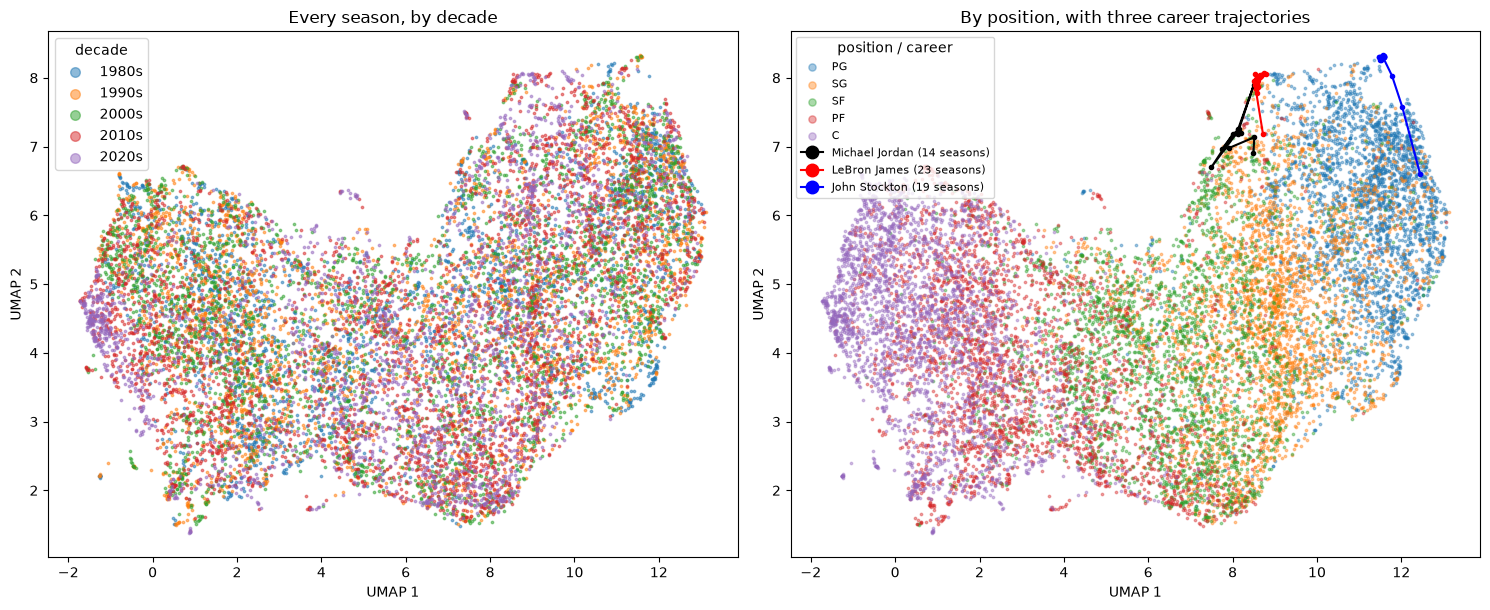

Rows with a position: 14672 of 14672
UMAP on every season's embedding (n_neighbors 15, min_dist 0.1, metric cosine, random_state 2026). Trustworthiness (10 neighbours, 3,000-season sample): **0.928** (1.0 = every 2D neighbourhood is a real neighbourhood). The map is 


In [4]:
m = umap_xy.merge(pool[["player_id", "season", "pos"]], on=["player_id", "season"], how="left", validate="1:1")
m["decade"] = np.minimum((m["season"] // 10) * 10, 2020)
m["primary"] = m["pos"].astype(str).str.split("-").str[0]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for d in sorted(m["decade"].unique()):
    k = m["decade"] == d
    axes[0].scatter(m.loc[k, "x"], m.loc[k, "y"], s=3, alpha=0.5, label=f"{d}s")
axes[0].legend(markerscale=4, title="decade"); axes[0].set_title("Every season, by decade")
for p in ["PG", "SG", "SF", "PF", "C"]:
    k = m["primary"] == p
    axes[1].scatter(m.loc[k, "x"], m.loc[k, "y"], s=3, alpha=0.4, label=p)
for pid, colour in [("jordami01", "black"), ("jamesle01", "red"), ("stockjo01", "blue")]:
    t = m[m["player_id"] == pid].sort_values("season")
    axes[1].plot(t["x"], t["y"], "-o", c=colour, ms=3, lw=1.5, label=f"{name[pid]} ({len(t)} seasons)")
axes[1].legend(markerscale=3, fontsize=8, title="position / career"); axes[1].set_title("By position, with three career trajectories")
for ax in axes:
    ax.set(xlabel="UMAP 1", ylabel="UMAP 2")
plt.tight_layout(); plt.show()
print("Rows with a position:", int(m["primary"].isin(["PG", "SG", "SF", "PF", "C"]).sum()), "of", len(m))
print(next(l for l in report_text.splitlines() if "Trustworthiness" in l)[:230])

## 4. What the app gets

Every export file, with its size and contents, read from `manifest.json` and the files themselves. The `exports/` folder is git-ignored and regenerated by `python src/precompute.py` (two runs give byte-identical files).

In [5]:
prof = np.load(EX / "profiles.npz")
rows = {
    "players.json": f"{len(players):,} players (name, seasons, decade, spread and its percentile)",
    "comps.json": f"{len(comps):,} players x {len(next(iter(comps.values())))} comps (id, rank, score)",
    "why.json": f"{len(why):,} players x {len(next(iter(why.values())))} comps x {len(next(iter(next(iter(why.values())).values())))} features",
    "seasons_umap.csv": f"{len(umap_xy):,} seasons (x, y)",
    "profiles.npz": f"{prof['centre'].shape[0]:,} players: centre {prof['centre'].shape[1]}-d, peak {prof['peak'].shape[1]}-d, spread, scales {np.round(prof['scales'], 3).tolist()}",
}
table = pd.DataFrame([{"file": f, "bytes": f"{v['bytes']:,}", "sha256 (first 16)": v["sha256"][:16], "contents": rows[f]}
                      for f, v in manifest["files"].items()]).set_index("file")
display(table)
print(f"Total {sum(v['bytes'] for v in manifest['files'].values()) / 1e6:.1f} MB; counts in manifest: {manifest['counts']}")
assert manifest["counts"]["players"] == len(players) and manifest["counts"]["seasons"] == len(umap_xy)
for f, v in manifest["files"].items():
    assert f"| {f} | {v['bytes']:,} | {v['sha256'][:16]} |" in report_text, f"report disagrees on {f}"
print("Matches reports/phase6_explain.md")

,bytes,sha256 (first 16),contents
file,,,
players.json,"434,962",7b9f8618ff7887ea,"2,467 players (name, seasons, decade, spread a..."
comps.json,"1,415,328",365efcce02d3d37e,"2,467 players x 10 comps (id, rank, score)"
why.json,"4,884,715",93f59c43bea04cd8,"2,467 players x 5 comps x 15 features"
seasons_umap.csv,"424,978",72cbb13c27a4c756,"14,672 seasons (x, y)"
profiles.npz,"1,237,952",6a4b008c0c43b9ba,"2,467 players: centre 32-d, peak 32-d, spread,..."


Total 8.4 MB; counts in manifest: {'players': 2467, 'seasons': 14672, 'players_explained': 2467}
Matches reports/phase6_explain.md


## 5. Findings

- **The explanations pass both faithfulness checks.** Completeness error averages 0.106% over all 12,335 explained pairs (0.123% on this notebook's 50), with a maximum of 2.329%; the share of pairs under 1% reads 100.0% only after rounding, since the maximum shows at least one pair above it. In the deletion test, removing a player's 3 most-credited stats drops the score by 0.754 on average against 0.224 for 3 random stats (300 pairs; 0.814 against 0.246 on this notebook's 50), and the top 3 matter more in 100% of pairs (section 2).
- **The breakdowns read like basketball.** Jordan and Kobe are alike on usage, shot volume and steals; Rodman and Reggie Evans on offensive and defensive rebounding; Stockton and Chris Paul on assists and steals (section 1).
- **The map places every season,** 14,672 of 14,672, and its trustworthiness is 0.928 (section 3). It is for display only: comps never use it.
- **The app gets five files, 8.4 MB in total:** 2,467 players with 10 comps each, a 15-feature breakdown for each player's top 5, map coordinates for every season, and the profile vectors for the live lambda slider (section 4). The full report records identical checksums across two runs.
- **Caveat:** the explanations describe the model's scores, not basketball truth, and the deletion test is run on the first player's side of each pair only.